<a href="https://colab.research.google.com/github/Sreehari05055/group_project/blob/main/group_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## COMP5712M: Programming for Data Science

## Group project: Data Analysis Project


# Analysing the Effect of Holidays on Walmart Sales Performance


* __Sreehari Anukumar__, _wvnp0245_@leeds.ac.uk
* __Harsha Vardhan Reddy Pannala__, _bpsj0972_@leeds.ac.uk
* __Sauban Imtiaz Khan__, _xwwf0372_@leeds.ac.uk
* _NameD_, _usernameD_@leeds.ac.uk


# Project Plan

## Description of Dataset

This project uses weekly Walmart sales from 5 February 2010 to 26 October 2012. The file contains 6,435 rows, one row for each of 45 stores in each of 143 weeks, and eight features covering sales, holiday weeks, and local conditions. The dataset was obtained from Kaggle’s Walmart weekly sales collection, which records store-level sales together with holiday and economic indicators (Yasser, 2021). 

Each row is one store in one week. `Store` is only an identity number, from 1 to 45, so the same store can be followed from week to week. `Date` is the week those sales belong to. The weeks run from 5 February 2010 to 26 October 2012. Dates are stored day-first, so `05-02-2010` is read as 5 February 2010. There are no missing values, and every store has the same 143 weeks of data.

`Weekly_Sales` is the total sales revenue for that store in that particular week, in US dollars. The quietest store-week is about USD 209,986 and the busiest is about USD 3,818,686, so the largest weeks are more than fifteen times the smallest. The figure is the store total for that week. It does not record individual products or departments. 

`Holiday_Flag` is 1 in a holiday week and 0 in a normal week. The holiday weeks are the Super Bowl, Labour Day, Thanksgiving, and the Christmas week. The data ends on 26 October 2012, so Thanksgiving and Christmas appear twice each, once in 2010 and once in 2011. The Super Bowl and Labour Day also appear in 2012.

`Temperature` is the outside temperature where the store is, in degrees Fahrenheit. It runs from about −2 °F to about 100 °F. `Fuel_Price` is the local fuel price in US dollars, from about USD 2.47 to USD 4.47. `CPI` is the consumer price index, which shows how expensive everyday goods are in that area. It runs from about 126 to 227, and a higher number means higher prices. `Unemployment` is the percentage of people out of work in that area, from about 3.9% to 14.3%.








# Project Aim & Objectives

## Project Aim
The main aim of this project is to investigate which holiday events actually lift weekly sales across Walmart stores, and how those sales increases differ across stores and weather conditions. Retail holidays like the Super Bowl, Labour Day, Thanksgiving, and Christmas are widely assumed to produce large spikes in retail revenue. However, different holidays happen at different times of the year, under different temperatures, and across stores of very different sizes. By analysing 143 weeks of sales data across 45 stores, this project aims to measure the real sales increase associated with holiday weeks, separating genuine holiday lifts from normal weekly fluctuations and local conditions.

### Specific Objectives
* __Objective 1:__ Track sales in the weeks before, during, and after each holiday to see whether holidays cause an immediate spike or whether shoppers buy in advance.
* __Objective 2:__ Compare average weekly sales for each holiday type against normal non-holiday weeks to see which holidays create the largest overall increase.
* __Objective 3:__ Identify which individual stores gain the most sales during Thanksgiving, Christmas, Super Bowl, and Labour Day, and which stores see little or no change.
* __Objective 4:__ Evaluate whether holiday sales differ between cold, mild, and hot weather by comparing holiday weeks with normal weeks within the same temperature band.


# System Design

### Architecture
The project follows a modular data processing pipeline in Python. The dataset (`Walmart_Sales.csv`) is first loaded and validated for missing values and correct data types. The clean data then passes through specific processing modules corresponding to each project objective, computing store gains and temperature band summaries. Finally, the processed outputs are fed into visualisation functions to produce clear comparative charts and tables for the report.

```
                                               +----------------------+
                                               |  Walmart_Sales.csv   |
                                               +----------------------+
                                                           |
                                                           v
                                               +----------------------+
                                               | Data Validation and  |
                                               | Date Formatting      |
                                               +----------------------+
                                                           |
              +-----------------------------+--------------+--------------+-----------------------------+
              |                             |                             |                             |
              v                             v                             v                             v
+---------------------------+ +---------------------------+ +---------------------------+ +---------------------------+
| Objective 1: Before/After | | Objective 2: Holiday      | | Objective 3: Store        | | Objective 4: Temp         |
| Holiday Flag Filtering    | | Mean Sales & Spread       | | Gain Calculations         | | Band Summaries & Lift     |
+---------------------------+ +---------------------------+ +---------------------------+ +---------------------------+
              |                             |                             |                             |
              +-----------------------------+--------------+--------------+-----------------------------+
                                                           |
                                                           v
                                               +----------------------+
                                               | Visualisations and   |
                                               | Results Overview     |
                                               +----------------------+
```

### Processing Modules and Algorithms
1. __Data Validation and Parsing:__ Checks required column names, handles missing values, and converts day-first string dates into pandas datetime objects.
2. __Surrounding Weeks (Objective 1):__ Averages sales across the 45 stores for each week, then takes the two weeks before a holiday, the holiday week, and the two weeks after, and compares those five averages with the overall weekly average.
3. __Holiday Means (Objective 2):__ Labels each week as a normal week or as the Super Bowl, Labour Day, Thanksgiving, or Christmas from the calendar month, then compares the mean weekly sales of each holiday with the normal-week mean.
4. __Holiday Filtering (Objective 3):__ Identifies holiday weeks (`Holiday_Flag == 1`) and maps each week to its holiday type based on the calendar month (February: Super Bowl, September: Labour Day, November: Thanksgiving, December: Christmas).
5. __Store Gain Calculation (Objective 3):__ Computes each store's average sales on holiday weeks minus its normal weekly average, sorting stores to identify top and bottom performers.
6. __Temperature Discretisation & Lift (Objective 4):__ Categorises temperature into Cold (under 45°F), Mild (45-70°F), and Hot (over 70°F) bands, and computes the controlled dollar gain and percentage lift against normal weeks in the same band.
7. __Visualisation Modules:__ Generates horizontal ranking bar charts, box plots, and grouped bar charts using matplotlib.


# Program Code

#### Objective 1: Track sales in the weeks before, during, and after each holiday to see whether holidays cause an immediate spike or whether shoppers buy in advance.

In [21]:
# Imports required to achieve objective
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

Before we can begin working on the dataframe, first we need to validate it. That way any errors in the dataset can be caught before they cause problems with the analysis.

In [22]:
def validate_dataframe(df):
    """Validate the columns and values needed by the analysis."""
    required = {"Date", "Store", "Weekly_Sales", "Holiday_Flag"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Missing column: {', '.join(sorted(missing))}.")
    if df.empty:
        raise ValueError("Walmart_Sales.csv contains no data.")
    if df[list(required)].isna().any().any():
        raise ValueError("Date, Store, Weekly_Sales, and Holiday_Flag cannot contain missing values.")

    try:
        pd.to_numeric(df["Weekly_Sales"])
    except (TypeError, ValueError):
        raise ValueError("Weekly_Sales must contain numeric values.") from None
    if (pd.to_numeric(df["Weekly_Sales"]) < 0).any():
        raise ValueError("Weekly_Sales cannot contain negative values.")

    holiday_flags = set(pd.to_numeric(df["Holiday_Flag"], errors="coerce").dropna().unique())
    if not holiday_flags.issubset({0, 1}):
        raise ValueError("Holiday_Flag must contain only 0 or 1.")
    if not (df["Holiday_Flag"] == 1).any():
        raise ValueError("The dataset contains no holiday weeks.")

    parsed_dates = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
    if parsed_dates.isna().any():
        raise ValueError("Date values must use day-first format such as 05-02-2010.")


In order to figure out how holiday weeks affect sales, we need to calculate the average weekly sales across each store. The function below does that, and returns a new dataframe with the average weekly sales for each week in the dataset.

In [23]:
def calculate_average_weekly_sales(df):
    data = df.copy()
    data["Date"] = pd.to_datetime(data["Date"], format="%d-%m-%Y", errors="coerce")
    if data["Date"].isna().any():
        raise ValueError("A Date value could not be read.")

    average_weekly_sales = (
        data.groupby("Date", as_index=False)["Weekly_Sales"]
        .mean()
        .rename(columns={"Weekly_Sales": "Average_Weekly_Sales"})
        .sort_values("Date")
        .reset_index(drop=True)
    )
    return average_weekly_sales


Once we have combined the average weekly sales, we then calculate the average sales for the two weeks before, the holiday week itself, and the two weeks after. The function below does that, and returns a new dataframe with the average weekly sales for each of those five weeks.

In [24]:
def calculate_holiday_surrounding_averages(df, average_weekly_sales):
    holiday_dates = set(
        pd.to_datetime(
            df.loc[df["Holiday_Flag"].eq(1), "Date"],
            format="%d-%m-%Y",
            errors="coerce",
        ).dropna()
    )

    weekly_dates = average_weekly_sales["Date"].tolist()
    positions = []
    for holiday_date in holiday_dates:
        try:
            holiday_position = weekly_dates.index(holiday_date)
        except ValueError:
            continue

        for offset in (-2, -1, 0, 1, 2):
            position = holiday_position + offset
            if 0 <= position < len(average_weekly_sales):
                positions.append({
                    "Relative_Week": offset,
                    "Average_Weekly_Sales": (
                        average_weekly_sales.iloc[position]["Average_Weekly_Sales"]
                    ),
                })

    surrounding = pd.DataFrame(positions)
    if surrounding.empty:
        raise ValueError("No holiday weeks were found.")

    return (
        surrounding.groupby("Relative_Week", as_index=False)["Average_Weekly_Sales"]
        .mean()
        .sort_values("Relative_Week")
        .reset_index(drop=True)
    )

Now that we have the average weekly sales for the two weeks before, the holiday week itself, and the two weeks after, we can plot that data to see how holiday weeks affect sales. The function below does that, and returns a matplotlib figure with the plot. To help show the effect of holiday weeks, the overall average weekly sales is also plotted as a dashed line.

In [25]:
def plot_holiday_surrounding_averages(surrounding, overall_average):
    """Plot average sales for two weeks before through two weeks after holidays."""
    fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
    ax.plot(
        surrounding["Relative_Week"],
        surrounding["Average_Weekly_Sales"] / 1000,
        color="#4c72b0",
        linewidth=2,
        marker="o",
    )
    ax.axhline(
        overall_average / 1000,
        color="#55a868",
        linestyle="--",
        linewidth=1.5,
        label=f"Full-year average: ${overall_average / 1000:.1f}k",
    )
    ax.set_title("Average Weekly Sales Around Holiday Weeks")
    ax.set_xlabel("Relative Week (0 = holiday week)")
    ax.set_ylabel("Average Weekly Sales ($ thousands)")
    ax.set_xticks([-2, -1, 0, 1, 2])
    ax.axvline(0, color="#c44e52", linestyle="--", linewidth=1.5)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.legend()
    return fig

The code below is ran to create the dataframe that will be used to plot the graph showing the average weekly sales for the two weeks before, the holiday week itself, and the two weeks after. The overall average weekly sales is also calculated to be plotted as a dashed line. It first validates the dataframe, then calculates the average weekly sales, and finally calculates the average sales for the two weeks before, the holiday week itself, and the two weeks after. The resulting dataframe is printed to show the average weekly sales for each of those five weeks. That dataframe can then be used to plot a graph showing how holiday weeks affect sales.

   Relative_Week  Average_Weekly_Sales
0             -2          1.078307e+06
1             -1          1.180476e+06
2              0          1.122888e+06
3              1          1.034048e+06
4              2          1.013826e+06


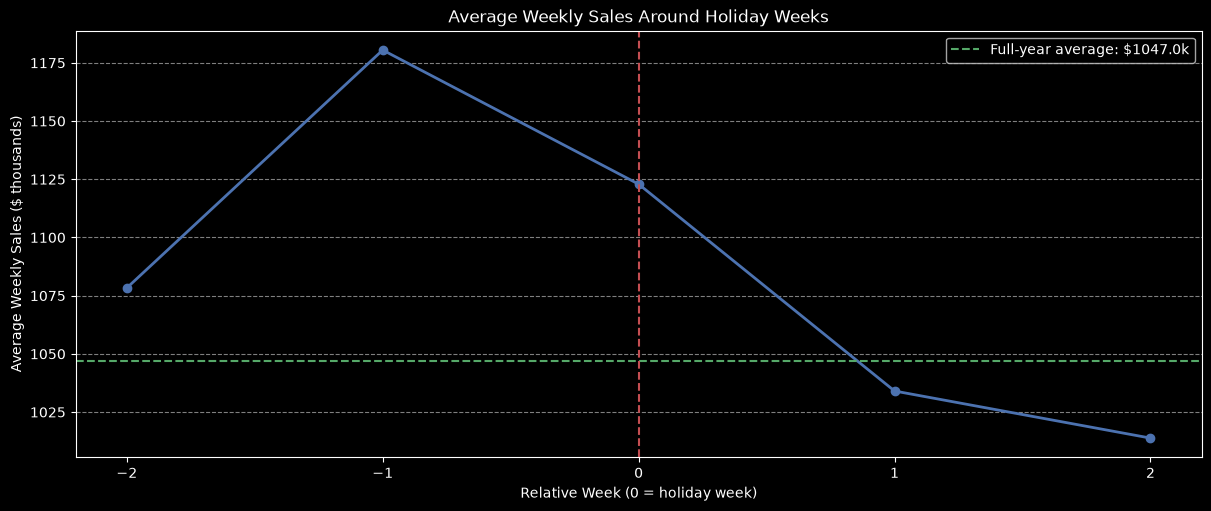

In [ ]:
try:
    df = pd.read_csv("Walmart_Sales.csv")
except FileNotFoundError:
    raise FileNotFoundError("Walmart_Sales.csv was not found in the current folder.") from None
except pd.errors.EmptyDataError:
    raise ValueError("Walmart_Sales.csv is empty.") from None

validate_dataframe(df)
average_weekly_sales = calculate_average_weekly_sales(df)
surrounding = calculate_holiday_surrounding_averages(df, average_weekly_sales)
overall_average = average_weekly_sales["Average_Weekly_Sales"].mean()
print(surrounding)


#### Objective 2: Mean sales for each holiday type against a normal week 

In Objective 2, we find out which holidays are lifting sales above a normal week. It compares mean weekly sales for a normal week against the Super Bowl, Labour Day, Thanksgiving, and Christmas. Here, a bar chart shows the mean for each group, while a box plot shows the spread of weekly sales within each group.

to reach our objective we start by importing `pandas` , `matplotlib.pyplot` and `Line2D` from `matplotlib.lines` and we set 5 groups and their respective colours for their upcoming visualisations  

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

GROUPS = ("Normal Week", "Super Bowl", "Labour Day", "Thanksgiving", "Christmas")
COLOURS = ["#8c8c8c", "#4c72b0", "#55a868", "#dd8452", "#c44e52"]

Here `label_weeks` takes the raw data as input, which has a day-first `Date`, a `Holiday_Flag` of 1 or 0, and `Weekly_Sales`. It returns a copy with `Date` converted to real dates and a new `Group` column. Unflagged weeks are labelled `Normal Week`, and flagged weeks are named from the month, for example, February is the Super Bowl, and September is Labour Day. We have also set up checks for a missing column, a date that could not be read, and a flagged week outside those four months, and an error is raised if any of these occur.

In [2]:
def label_weeks(df):
    """We add a Group column: Normal Week, or the holiday the flagged week belongs to."""
    needed = {"Date", "Holiday_Flag", "Weekly_Sales"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Missing column: {', '.join(sorted(missing))}.")
    df = df.copy()

    # Keep the original data unchanged.
    # Dates are day-first (05-02-2010). Unreadable ones become NaT so we can catch them below.
    dates = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
    if dates.isna().any():
        raise ValueError("A Date value could not be read. Dates must be day-first, such as 05-02-2010.")
    df["Date"] = dates

    # Holiday_Flag is only 1 or 0, so the month tells us which holiday it is
    # (2 is February, 9 is September, 11 is November, 12 is December).
    month_to_holiday = {2: "Super Bowl", 9: "Labour Day", 11: "Thanksgiving", 12: "Christmas"}
    df["Group"] = "Normal Week"
    flagged = df["Holiday_Flag"].eq(1)
    df.loc[flagged, "Group"] = df.loc[flagged, "Date"].dt.month.map(month_to_holiday)
    if df["Group"].isna().any():
        raise ValueError("A holiday week is not in February, September, November, or December.")
    return df

In `group_means`, the labelled data from `label_weeks` goes in as input. It returns the mean weekly sales for each of the five groups defined earlier, in a fixed order, averaged over all stores and years. We have also set up a check for a group with no rows at all, which would otherwise show up as empty space on the chart, and an error is raised if this happens.

In [3]:
def group_means(df):
    """Mean weekly sales for each group, averaged over all stores and years."""
    # reindex puts the groups in our fixed order and gives NaN to any group with no rows.
    means = df.groupby("Group")["Weekly_Sales"].mean().reindex(GROUPS)
    if means.isna().any():
        raise ValueError(f"No rows for: {', '.join(means.index[means.isna()])}.")
    return means

in `plot_mean_bars` the input is the `means` from `group_means`, the number of store-weeks we have in each group, and that results in a bar chart which shows a dashed line at the normal week mean where each bar is labelled with its own mean and n, and each holiday bar also has its percentage lift over the normal week. there are no checks of its own but it does rely on `group_means` having rejected an empty group beforehand

In [4]:
def plot_mean_bars(means, counts):
    """Bar chart of the group means, with a dashed line at the normal week mean."""
    fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")

    # Divide by 1 million so the axis is in millions of dollars.
    vals = means / 1e6
    bars = ax.bar(vals.index, vals.values, color=COLOURS)
    normal = vals["Normal Week"]
    ax.axhline(normal, color="black", linestyle="--", linewidth=0.8)

    gap = vals.max() * 0.02  # small space between the bar and its label
    for bar, name in zip(bars, vals.index):
        label = f"${vals[name]:.2f}M"
        if name != "Normal Week":
            label += f" ({(vals[name] / normal - 1) * 100:+.1f}%)"
        label += f"\nn = {counts[name]}"

        # Place the text above the higher of the bar and the dashed line,
        # so that a bar below normal (Christmas) does not get the line through its label.
        ax.text(bar.get_x() + bar.get_width() / 2, max(bar.get_height(), normal) + gap, label,
                ha="center", va="bottom", fontsize=9)

    ax.set_ylim(0, vals.max() * 1.2)
    ax.set_ylabel("Mean weekly sales ($ millions)")
    ax.set_title("Mean weekly sales: normal week vs holiday weeks")
    return fig

In `plot_box` the labelled data from `label_weeks` is taken as input and returns a box plot with one box per group, showing the median, the middle 50 percent which is the box itself and the outliers, with a diamond symbol for the mean. each group's n being the store-weeks is shown under its name.

In [5]:
def plot_box(df):
    """Box plot of weekly sales per group, so the spread shows as well as the mean."""
    data = [df.loc[df["Group"].eq(g), "Weekly_Sales"] / 1e6 for g in GROUPS]

    # millions, as in the bar chart
    fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
    box = ax.boxplot(data, patch_artist=True, showmeans=True,
                     medianprops={"color": "black"},
                     meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"},
                     flierprops={"markersize": 3, "alpha": 0.4})

    # Names are set after drawing because the boxplot argument for them (labels or
    # tick_labels) differs between matplotlib versions. Boxes sit at positions 1 to 5.
    ax.set_xticks(range(1, len(GROUPS) + 1))
    ax.set_xticklabels([f"{g}\n(n = {len(d)})" for g, d in zip(GROUPS, data)])
    for patch, colour in zip(box["boxes"], COLOURS):
        patch.set_facecolor(colour)
        patch.set_alpha(0.8)
    ax.legend(handles=[
        Line2D([], [], marker="D", color="black", markerfacecolor="white", linestyle="", label="Mean"),
        Line2D([], [], color="black", label="Median"),
    ], loc="upper right")
    ax.set_ylabel("Weekly sales ($ millions)")
    ax.set_title("Spread of weekly sales: normal week vs holiday weeks")
    return fig

We load the dataset and label each week and we get the number of store weeks for each group, and `counts` is reused for the `n` labels on the charts

In [6]:
df = pd.read_csv("Walmart_Sales.csv")
df = label_weeks(df)
counts = df["Group"].value_counts()
counts.reindex(GROUPS)

Group
Normal Week     5985
Super Bowl       135
Labour Day       135
Thanksgiving      90
Christmas         90
Name: count, dtype: int64

After working out the mean sales for each group we get the output table showing the median and spread, and the lift compared to a normal week. thanksgiving is the only holiday which is well above normal and christmas is below it The table also has a `weeks_above_typical_%` column, which is the share of store-weeks that sell more than a typical normal week, where typical means the normal week median. This is about 50% for normal weeks by definition, so it shows how far each holiday moves away from that.

In [7]:
means = group_means(df)

summary = df.groupby("Group")["Weekly_Sales"].agg(["count", "mean", "median", "std"]).reindex(GROUPS)

# Lift is how far each group's mean is above or below the normal week mean, in percent.
summary["lift_vs_normal_%"] = (summary["mean"] / summary.loc["Normal Week", "mean"] - 1) * 100

# A typical normal week is the normal-week median. This is the share of store-weeks above it.
typical = summary.loc["Normal Week", "median"]
summary["weeks_above_typical_%"] = (
    df["Weekly_Sales"].gt(typical).groupby(df["Group"]).mean().reindex(GROUPS) * 100
)
summary.round(1)

,count,mean,median,std,lift_vs_normal_%,weeks_above_typical_%
Group,,,,,,
Normal Week,5985,1041256.4,956211.2,558957.4,0.0,50.0
Super Bowl,135,1079128.0,1015654.6,576945.6,3.6,54.8
Labour Day,135,1042427.3,976415.6,537894.3,0.1,51.9
Thanksgiving,90,1471273.4,1327536.2,797247.5,41.3,70.0
Christmas,90,960833.1,889822.0,503227.4,-7.7,44.4


#### Objective 3: Compare each store’s holiday-week sales with its normal-week sales for the Super Bowl, Labour Day, Thanksgiving, and Christmas, and identify the stores with the largest gains and the largest losses relative to a normal week.

To achieve objective 3, `pandas`, `matplotlib.pyplot`, and `Patch` from `matplotlib.patches` were imported, as shown in the code block below.

In [8]:
# Imports required to achieve objective 

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

`filter_holidays` splits the file into holiday weeks and normal weeks. `Date` is read as a day-first date, such as `05-02-2010`. Weeks where `Holiday_Flag` is 1 are named from the month: February is the Super Bowl, September is Labour Day, November is Thanksgiving, and December is the Christmas week. The function returns those named holiday weeks, and the remaining weeks as normal weeks.

Three checks stop the function when this file is not in the expected shape. A missing `Date` or `Holiday_Flag` column raises an error. A blank or unreadable date raises an error, because every date in this file must be day-first. A holiday week outside February, September, November, or December raises an error. This file only flags the Super Bowl, Labour Day, Thanksgiving, and the Christmas week. Other holidays, for example Easter, may also occur, but they are not flagged here. A flagged week in another month would not match this dataset. These checks are written for this Walmart dataset. They would not apply to a generic dataset with different columns, date formats, or holidays.

In [9]:
def filter_holidays(df):
    """Split the weeks into named holiday weeks and normal weeks.

    February is the Super Bowl, September is Labour Day, November is
    Thanksgiving, and December is the Christmas week.
    """
    needed = {"Date", "Holiday_Flag"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Missing column: {', '.join(sorted(missing))}.")
    dates = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
    if dates.isna().any():
        raise ValueError("A Date value could not be read. Dates must be day-first, such as 05-02-2010.")
    df["Date"] = dates
    holiday = df["Holiday_Flag"].eq(1)
    holidays = df.loc[holiday].copy()

    # 2 is February, 9 is September, 11 is November, 12 is December.
    holidays["Holiday"] = holidays["Date"].dt.month.map(
        {2: "Super Bowl", 9: "Labour Day", 11: "Thanksgiving", 12: "Christmas"}
    )
    if holidays["Holiday"].isna().any():
        raise ValueError("A holiday week is not in February, September, November, or December.")
    return holidays, df.loc[~holiday].copy()

The cell below prints the first rows of both results. The first table is the holiday weeks, and the second is the normal weeks.

In [10]:
df = pd.read_csv("Walmart_Sales.csv")
holidays, normal = filter_holidays(df)
print(holidays.head())
print(normal.head())

    Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
1       1 2010-02-12    1641957.44             1        38.51       2.548   
31      1 2010-09-10    1507460.69             1        78.69       2.565   
42      1 2010-11-26    1955624.11             1        64.52       2.735   
47      1 2010-12-31    1367320.01             1        48.43       2.943   
53      1 2011-02-11    1649614.93             1        36.39       3.022   

           CPI  Unemployment       Holiday  
1   211.242170         8.106    Super Bowl  
31  211.495190         7.787    Labour Day  
42  211.748433         7.838  Thanksgiving  
47  211.404932         7.838     Christmas  
53  212.936705         7.742    Super Bowl  
   Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1 2010-02-05    1643690.90             0        42.31       2.572   
2      1 2010-02-19    1611968.17             0        39.93       2.514   
3      1 2010-02-26    1409727.59      

The `holiday_gain` function below takes the holiday weeks and the normal weeks from `filter_holidays` as input. For each store, it finds the average sales on each holiday and the average sales on that store's normal weeks. `Gain` is the holiday average minus the normal-week average. A positive gain means the holiday week sold more than a normal week. A negative gain means it sold less, which is a loss of sales relative to a normal week. 

In [11]:
def holiday_gain(holidays, normal):
    """Gain for each store on each holiday.

    Gain is that store's average sales on the holiday minus the same store's
    average sales on normal weeks. A positive gain means the holiday week sold
    more than a normal week. A negative gain means it sold less.
    """
    holiday_avg = holidays.groupby(["Store", "Holiday"], as_index=False)["Weekly_Sales"].mean()
    normal_avg = normal.groupby("Store", as_index=False)["Weekly_Sales"].mean()
    holiday_avg = holiday_avg.rename(columns={"Weekly_Sales": "Holiday_Avg"})
    normal_avg = normal_avg.rename(columns={"Weekly_Sales": "Normal_Avg"})
    gain = holiday_avg.merge(normal_avg, on="Store")
    # Gain is the holiday week minus that store's normal week.
    gain["Gain"] = gain["Holiday_Avg"] - gain["Normal_Avg"]
    return gain

The `plot_ranked_gains` function draws a horizontal bar chart with four panels, one each for the Super Bowl, Labour Day, Thanksgiving, and Christmas. For each holiday it keeps the 10 stores with the highest gain, in blue, and the 10 with the lowest gain, in red. The gain is shown in thousands of dollars. The function is called in Results Overview, where the chart is discussed.

In [12]:
def plot_ranked_gains(gain):
    """Bar chart of store gains for each holiday.

    One panel each for the Super Bowl, Labour Day, Thanksgiving, and Christmas.
    Blue bars are the 10 stores with the highest gain. Red bars are the 10
    stores with the lowest gain. The other stores are left out.
    """
    
    holidays = ("Super Bowl", "Labour Day", "Thanksgiving", "Christmas")
    fig, axes = plt.subplots(2, 2, figsize=(13, 11), layout="constrained")
    for ax, holiday in zip(axes.ravel(), holidays):
        part = gain.loc[gain["Holiday"].eq(holiday)].sort_values("Gain")
        if part.empty:
            raise ValueError(f"No rows for {holiday}, so the chart cannot be drawn.")
        show = pd.concat([part.head(10), part.tail(10)])
        
        # Divide by 1000 so the axis is in thousands of dollars.
        ax.barh(show["Store"].astype(str), show["Gain"] / 1000, color=["#c44e52"] * 10 + ["#4c72b0"] * 10)
        
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_title(holiday)
        ax.set_xlabel("Gain ($ thousands)")
        ax.set_ylabel("Store")
        ax.tick_params(axis="y", labelsize=8)
    fig.legend(handles=[
        Patch(color="#4c72b0", label="Top 10"),
        Patch(color="#c44e52", label="Bottom 10"),
    ], loc="outside lower center", ncol=2)
    fig.suptitle("Top 10 and bottom 10 stores by holiday gain")
    return fig

The output of `holiday_gain` is shown below. A negative gain is a loss of sales compared with that store's average normal week. A positive gain means the holiday week sold more than that normal week.

In [13]:
gain = holiday_gain(holidays, normal)
print(gain)

     Store       Holiday   Holiday_Avg    Normal_Avg           Gain
0        1     Christmas  1.432391e+06  1.546957e+06 -114566.020639
1        1    Labour Day  1.569900e+06  1.546957e+06   22942.367694
2        1    Super Bowl  1.698017e+06  1.546957e+06  151059.214361
3        1  Thanksgiving  1.994472e+06  1.546957e+06  447514.999361
4        2     Christmas  1.812331e+06  1.914209e+06 -101878.276880
..     ...           ...           ...           ...            ...
175     44  Thanksgiving  3.083878e+05  3.032536e+05    5134.132218
176     45     Christmas  7.742799e+05  7.821985e+05   -7918.613496
177     45    Labour Day  7.447008e+05  7.821985e+05  -37497.715163
178     45    Super Bowl  7.423673e+05  7.821985e+05  -39831.275163
179     45  Thanksgiving  1.176587e+06  7.821985e+05  394388.021504

[180 rows x 5 columns]


The `main` function block runs objective 3 from start to finish. It reads `Walmart_Sales.csv`, passes the table to `filter_holidays`, and passes those two results to `holiday_gain`. It then prints the gain table.

Before that, three checks protect the load. If `Walmart_Sales.csv` is not in the current folder, the function raises an error. If the file is empty, it raises an error. If `Store` or `Weekly_Sales` is missing, it raises an error. Those two columns are required by this dataset, so this column check would not apply to a generic file.

In [14]:
def main():
    """Main method of objective 3.

    Finds which stores gain the most sales on Thanksgiving, Christmas, Labour Day,
    and the Super Bowl, and which barely move.
    """
    try:
        df = pd.read_csv("Walmart_Sales.csv")
    except FileNotFoundError:
        raise FileNotFoundError("Walmart_Sales.csv was not found in the current folder.") from None
    except pd.errors.EmptyDataError:
        raise ValueError("Walmart_Sales.csv is empty.") from None
    needed = {"Store", "Weekly_Sales"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Missing column: {', '.join(sorted(missing))}.")

    holidays, normal = filter_holidays(df)
    gain = holiday_gain(holidays, normal)
    
    print(gain)

if __name__ == '__main__':
    main()

     Store       Holiday   Holiday_Avg    Normal_Avg           Gain
0        1     Christmas  1.432391e+06  1.546957e+06 -114566.020639
1        1    Labour Day  1.569900e+06  1.546957e+06   22942.367694
2        1    Super Bowl  1.698017e+06  1.546957e+06  151059.214361
3        1  Thanksgiving  1.994472e+06  1.546957e+06  447514.999361
4        2     Christmas  1.812331e+06  1.914209e+06 -101878.276880
..     ...           ...           ...           ...            ...
175     44  Thanksgiving  3.083878e+05  3.032536e+05    5134.132218
176     45     Christmas  7.742799e+05  7.821985e+05   -7918.613496
177     45    Labour Day  7.447008e+05  7.821985e+05  -37497.715163
178     45    Super Bowl  7.423673e+05  7.821985e+05  -39831.275163
179     45  Thanksgiving  1.176587e+06  7.821985e+05  394388.021504

[180 rows x 5 columns]


#### Objective 4: Compare sales across cold, mild, and hot holiday weeks.

Objective 4 investigates whether holiday weeks sell differently in cold, mild, or hot weather by comparing holiday sales against normal weeks in the exact same temperature band.

The `categorize_temperature` function below checks the required columns and splits temperatures into three bands: Cold (under 45°F), Mild (45-70°F), and Hot (over 70°F).

In [15]:
def categorize_temperature(df):
    """Split weeks into Cold (<45°F), Mild (45-70°F), and Hot (>70°F) temperature bands."""
    needed = {"Date", "Weekly_Sales", "Holiday_Flag", "Temperature"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Missing column: {', '.join(sorted(missing))}.")

    dates = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
    if dates.isna().any():
        raise ValueError("A Date value could not be read. Dates must be day-first, such as 05-02-2010.")

    data = df.copy()
    data["Date"] = dates
    data["Temp_Band"] = pd.cut(
        data["Temperature"],
        bins=[-float("inf"), 45.0, 70.0, float("inf")],
        labels=["Cold (<45°F)", "Mild (45-70°F)", "Hot (>70°F)"],
        right=True
    )
    return data


The cell below runs `categorize_temperature` on the Walmart dataset and shows the temperature band assigned to each row.

In [16]:
temp_df = categorize_temperature(df)
temp_df[["Date", "Temperature", "Temp_Band", "Holiday_Flag", "Weekly_Sales"]].head()


,Date,Temperature,Temp_Band,Holiday_Flag,Weekly_Sales
0,2010-02-05,42.31,Cold (<45°F),0,1643690.90
1,2010-02-12,38.51,Cold (<45°F),1,1641957.44
2,2010-02-19,39.93,Cold (<45°F),0,1611968.17
3,2010-02-26,46.63,Mild (45-70°F),0,1409727.59
4,2010-03-05,46.50,Mild (45-70°F),0,1554806.68


The `temperature_summary` function below groups sales by temperature band and holiday flag, calculating average sales, net dollar gains, and percentage lift between holiday weeks and normal weeks in the same band.

In [17]:
def temperature_summary(df):
    """Calculate mean weekly sales and lift for holiday vs normal weeks in each temperature band."""
    needed = {"Weekly_Sales", "Holiday_Flag", "Temp_Band"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Missing column: {', '.join(sorted(missing))}.")

    grouped = df.groupby(["Temp_Band", "Holiday_Flag"], observed=True)["Weekly_Sales"].agg(
        Count="count", Mean="mean", Median="median"
    ).reset_index()

    piv = grouped.pivot(index="Temp_Band", columns="Holiday_Flag", values="Mean")
    lift = piv[1] - piv[0]
    lift_pct = (lift / piv[0]) * 100

    rows = []
    for band in ["Cold (<45°F)", "Mild (45-70°F)", "Hot (>70°F)"]:
        n_row = grouped[(grouped["Temp_Band"] == band) & (grouped["Holiday_Flag"] == 0)].iloc[0]
        h_row = grouped[(grouped["Temp_Band"] == band) & (grouped["Holiday_Flag"] == 1)].iloc[0]
        rows.append({
            "Temp_Band": band,
            "Normal_Count": int(n_row["Count"]),
            "Normal_Mean": n_row["Mean"],
            "Holiday_Count": int(h_row["Count"]),
            "Holiday_Mean": h_row["Mean"],
            "Gain": lift[band],
            "Gain_Pct": lift_pct[band]
        })
    return pd.DataFrame(rows)


The summary table below shows the calculated gains for each temperature band. Gain is the holiday mean minus the normal mean in that same band.

In [18]:
temp_summary = temperature_summary(temp_df)
temp_summary


,Temp_Band,Normal_Count,Normal_Mean,Holiday_Count,Holiday_Mean,Gain,Gain_Pct
0,Cold (<45°F),1176,1.078059e+06,189,1.141952e+06,63893.645789,5.926731
1,Mild (45-70°F),2631,1.055586e+06,167,1.143122e+06,87535.646940,8.292610
2,Hot (>70°F),2178,1.004075e+06,94,1.048609e+06,44533.630984,4.435290


The `plot_holiday_temp_boxplot` function draws a box plot showing the distribution of weekly sales for holiday weeks across Cold, Mild, and Hot bands.

In [19]:
def plot_holiday_temp_boxplot(df):
    """Box plot of weekly sales for holiday weeks across Cold, Mild, and Hot bands."""
    holidays = df[df["Holiday_Flag"].eq(1)]
    bands = ["Cold (<45°F)", "Mild (45-70°F)", "Hot (>70°F)"]
    sales_by_band = [holidays[holidays["Temp_Band"].eq(b)]["Weekly_Sales"] / 1000 for b in bands]

    fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
    box = ax.boxplot(sales_by_band, patch_artist=True, labels=bands,
                     medianprops=dict(color="black", linewidth=1.5),
                     flierprops=dict(marker="o", markersize=4, alpha=0.5))

    colors = ["#4c72b0", "#55a868", "#c44e52"]
    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    ax.set_title("Holiday Weekly Sales Distribution by Temperature Band")
    ax.set_xlabel("Temperature Band")
    ax.set_ylabel("Weekly Sales ($ thousands)")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    return fig


The `plot_temperature_lift` function draws a grouped bar chart comparing normal weeks and holiday weeks side by side in each temperature band.

In [20]:
def plot_temperature_lift(summary_df):
    """Grouped bar chart comparing normal vs holiday mean sales in each temperature band."""
    bands = summary_df["Temp_Band"]
    fig, ax = plt.subplots(figsize=(8.5, 5), layout="constrained")
    x = range(len(bands))
    width = 0.35

    ax.bar([i - width/2 for i in x], summary_df["Normal_Mean"] / 1000, width,
           label="Normal Week", color="#4c72b0", alpha=0.85)
    ax.bar([i + width/2 for i in x], summary_df["Holiday_Mean"] / 1000, width,
           label="Holiday Week", color="#dd8452", alpha=0.85)

    ax.set_title("Mean Weekly Sales: Normal vs Holiday Weeks by Temperature Band")
    ax.set_xlabel("Temperature Band")
    ax.set_ylabel("Mean Sales ($ thousands)")
    ax.set_xticks(list(x))
    ax.set_xticklabels(bands)
    ax.legend(frameon=True)
    ax.grid(axis="y", linestyle="--", alpha=0.5)

    for i, row in summary_df.iterrows():
        label = f"+{row['Gain_Pct']:.1f}%"
        ax.annotate(label, (i + width/2, row["Holiday_Mean"] / 1000),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, fontweight="bold")
    return fig


The `main` function block runs objective 4 from start to finish, reading `Walmart_Sales.csv`, categorising temperatures, printing the summary table, and plotting both figures.

In [21]:
def main():
    """Main method of objective 4."""
    try:
        df = pd.read_csv("Walmart_Sales.csv")
    except FileNotFoundError:
        raise FileNotFoundError("Walmart_Sales.csv was not found in the current folder.") from None
    except pd.errors.EmptyDataError:
        raise ValueError("Walmart_Sales.csv is empty.") from None

    data = categorize_temperature(df)
    summary = temperature_summary(data)
    print(summary[["Temp_Band", "Normal_Mean", "Holiday_Mean", "Gain", "Gain_Pct"]])

    plot_holiday_temp_boxplot(data)
    plot_temperature_lift(summary)
    plt.show()


# Results Overview

### Objective 1

#### Explanation of Results

Objective 1 investigates how holiday weeks affect sales in the surrounding weeks. The chart shows that average weekly sales rise in the two weeks before a holiday, peak in the holiday week itself, and then fall below the overall average in the two weeks after.

The line chart below shows the average weekly sales for the two weeks before, the holiday week itself, and the two weeks after. The dashed line is the overall average weekly sales across all 143 weeks in the dataset. The blue line shows the average weekly sales for weeks surrounding the holidays. The x-axis shows the relative week, where 0 is the holiday week, -1 is the week before, -2 is two weeks before, +1 is the week after, and +2 is two weeks after. The y-axis shows the average weekly sales in thousands of dollars.

The green dotted line shows the overall average weekly sales across all 143 weeks in the dataset. That is used as a comparison point to show how holiday weeks lift sales above the average, and how the weeks after a holiday fall below that average.

By comparing the blue line to the green line we can see that that holidays lift sales in the two weeks before, but the largest lift is in the holiday week itself. After the holiday, sales fall below the overall average for two weeks. The chart shows that holidays do not just impact sales in the holiday week itself, but also in the surrounding weeks. Stores can expect to see an increase of sales in the two weeks before a holiday, and a decrease in the two weeks after and can use that information to plan staffing, inventory, and marketing campaigns.


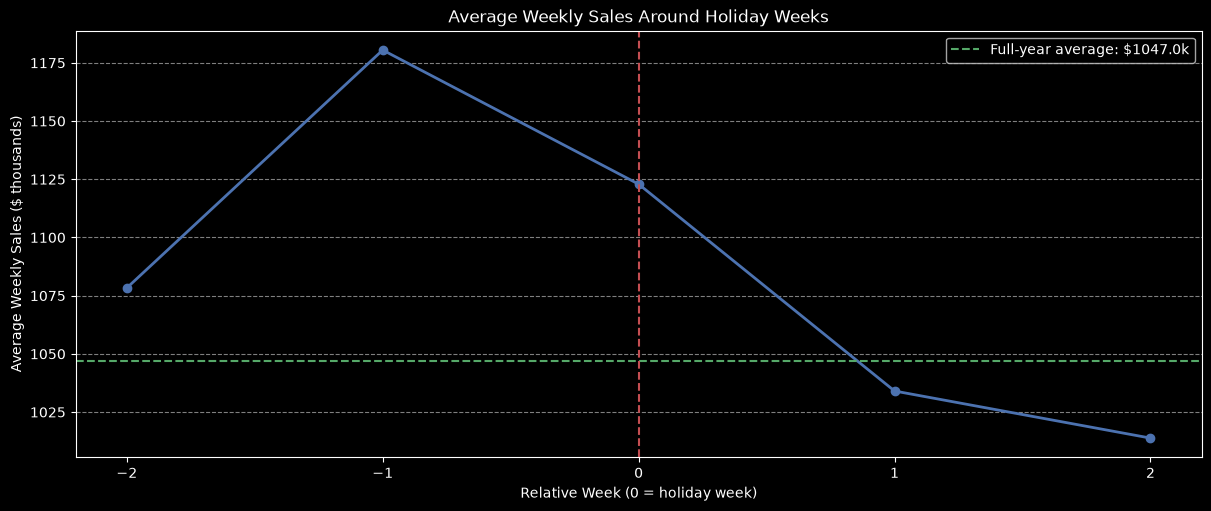

In [43]:
plot_holiday_surrounding_averages(surrounding, overall_average)
plt.show()

### Objective 2

#### Explanation of Results

Objective 2 shows that Thanksgiving has the largest lift in sales over a normal week. A normal week averages about USD 1.04M per store, while Thanksgiving averages about USD 1.47M, which is a lift of 41.3%. Its median is also well above the normal median, USD 1.33M against USD 0.96M, which suggests the increase is not due to a few extremes.

The other holidays barely move. The Super Bowl is 3.6% above normal at USD 1.08M, and Labour Day is almost the same as a normal week with a 0.1% increase, while Christmas is below normal at USD 0.96M, which is a drop of 7.7%.
    
The box plot shows the spread as well as the mean. The Thanksgiving box sits higher than the others, with its middle 50 percent running roughly from USD 0.8M to USD 2.0M. The boxes for normal weeks, the Super Bowl, and Labour Day overlap a lot, which makes their differences small compared with the spread, so they cannot be treated as clear lifts.
    
Normal weeks also have the highest outliers, which reach about USD 3.8M. These come from the weeks ending 17 and 24 December 2010 and 23 December 2011, which hold every normal week value above USD 2.8M. This is the pre-Christmas rush, which the dataset does not flag as a holiday, so it is counted as a normal week.
    
This also explains why the Christmas result needs caution. The dates in the file are Fridays and appear to be week endings, since all holidays fall inside their flagged week on that reading. The flagged Christmas weeks end on 31 December 2010 and 30 December 2011. They come after the main shopping rush, so they miss the peak, and this is the main reason Christmas looks weak. The rush also slightly raises the normal baseline, but removing those three weeks only moves the normal mean from USD 1.04M to USD 1.03M, so it explains only a small part of the gap.
    
Overall, Thanksgiving has the largest lift, the Super Bowl and Labour Day show little change, and the flagged Christmas week does not lift sales in this data.

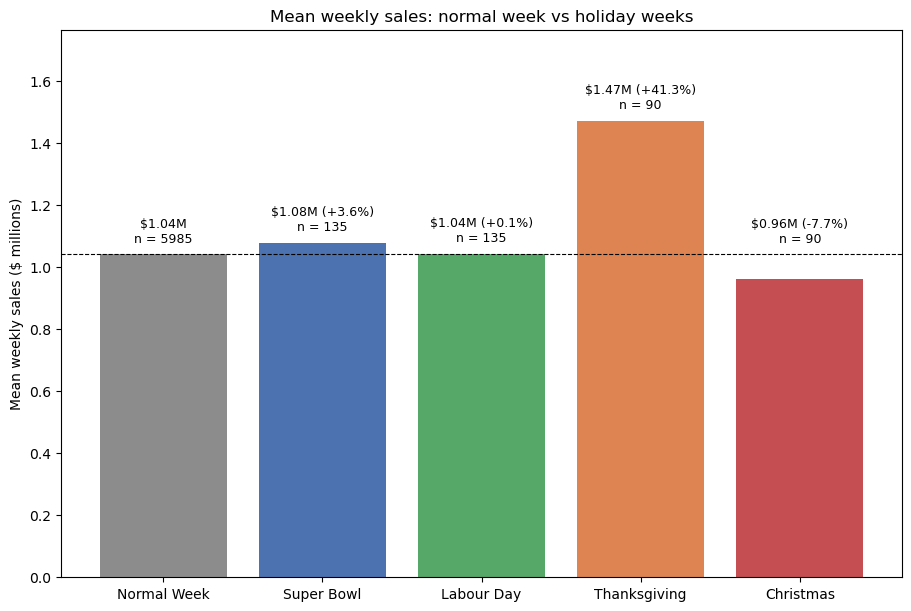

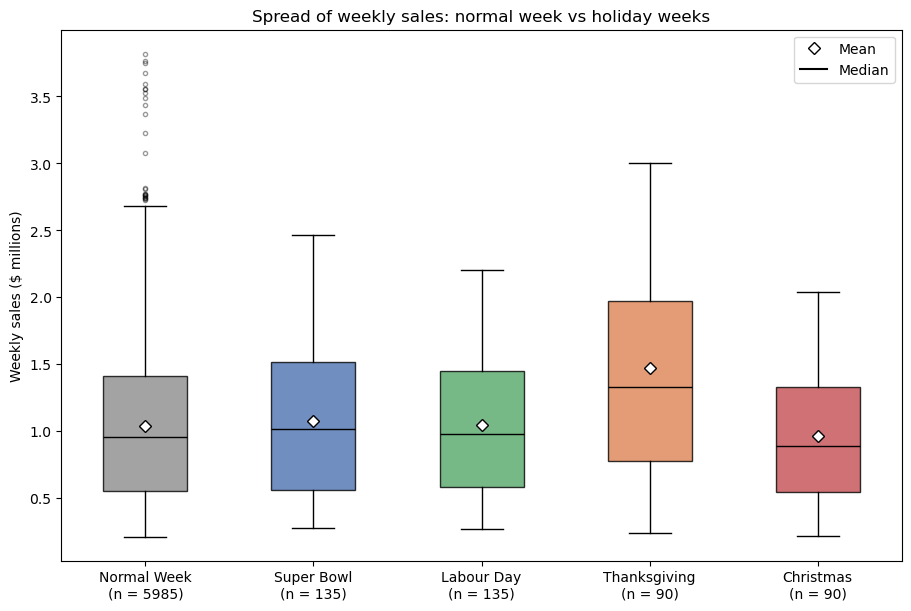

In [22]:
labelled_df = label_weeks(pd.read_csv("Walmart_Sales.csv"))   # df was reloaded in Objective 3, so label it again

plot_mean_bars(means, counts)
plt.show()
plot_box(labelled_df)
plt.show()

### Objective 3

#### Explanation of Results

The horizontal bar chart below shows, for each holiday, the 10 stores with the highest gain and the 10 with the lowest. Gain is that store's holiday-week average minus its normal-week average.

Objective 3 compares each store's holiday-week sales with its own normal-week sales for the Super Bowl, Labour Day, Thanksgiving, and Christmas, and identifies the stores with the largest gains and the largest losses relative to a normal week.

The chart keeps the 10 highest gains in blue and the 10 lowest in red. The axis is in thousands of dollars. A positive bar is higher sales than that store's normal week. A negative bar is a loss of sales relative to that normal week, not a loss in the accounts.

Thanksgiving shows the largest gains. Store 10 is the highest, about USD 1.06 million above its normal week. Only four stores in the whole set are below a normal week on Thanksgiving, and the largest of those falls is about USD 12,000 at store 33. Most of the red bars are still above zero, so even the lowest Thanksgiving weeks are close to a normal week or only slightly below it.

The Super Bowl also lifts sales, but by less. Store 10 is again the highest, at about USD 287,000 above its normal week. Twelve stores are below a normal week. Store 39 is the lowest, at about USD 131,000 below.

Labour Day is mixed. Store 17 has the highest gain, about USD 319,000. Store 10, which gains the most at Thanksgiving and the Super Bowl, has the lowest Labour Day result, about USD 184,000 below its normal week. Twenty-six stores are below a normal week.

Christmas is the weakest of the four holidays in this file. Forty-one of the 45 stores are below a normal week. Store 7 is the highest, at about USD 210,000 above its normal week, and store 14 is the lowest, at about USD 245,000 below. The largest fall is bigger than the largest gain. The Christmas flag is the week ending 31 December 2010 and 30 December 2011, the week after the main shopping week.

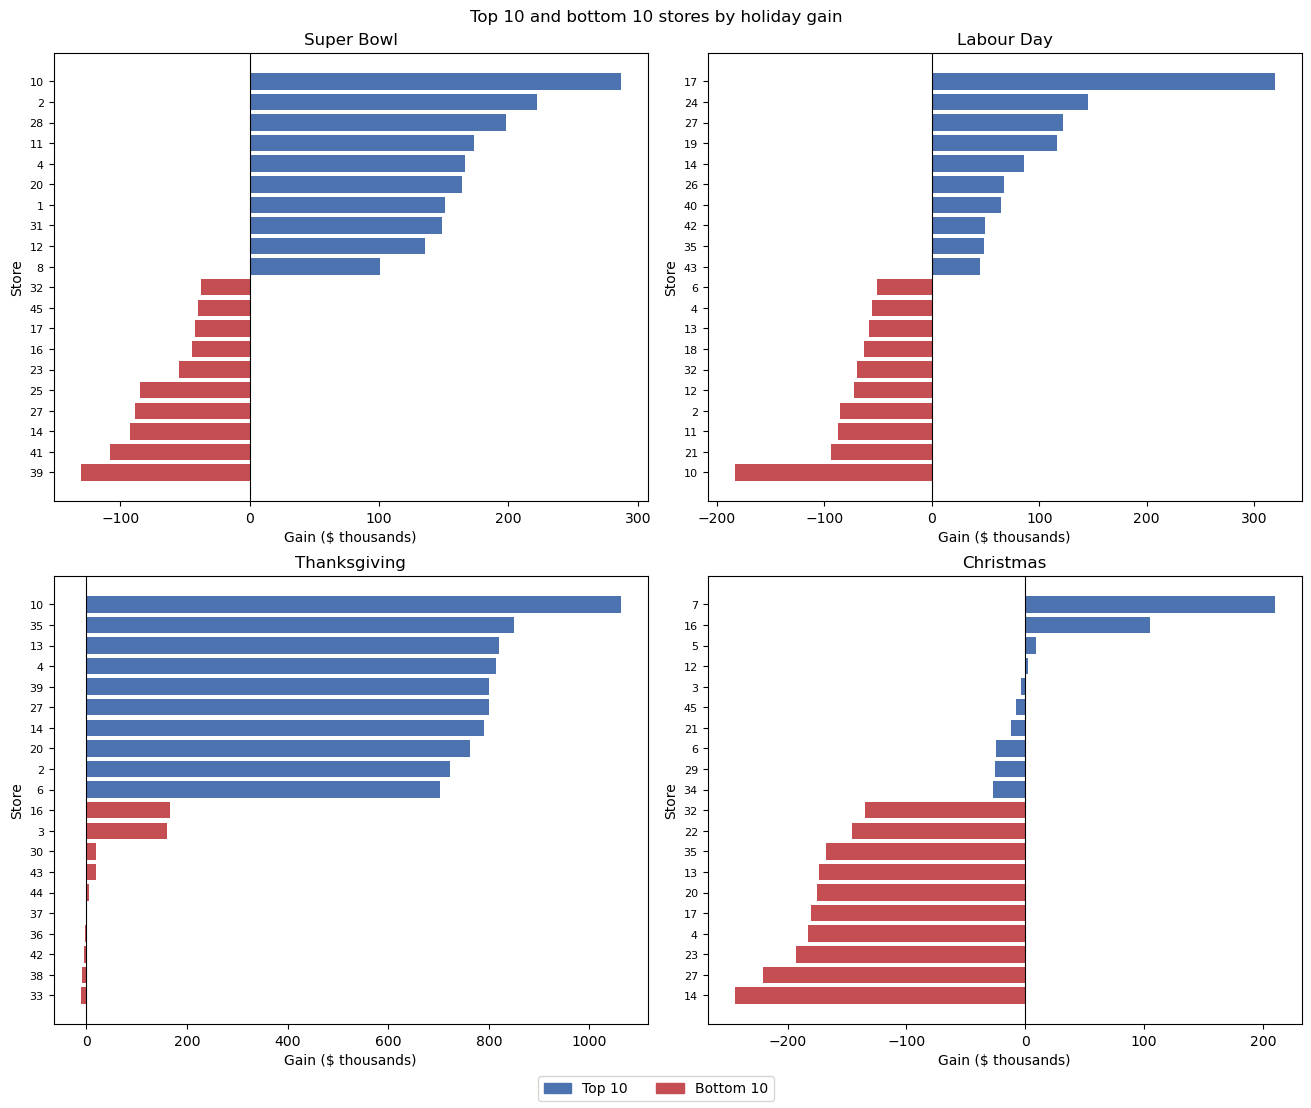

In [23]:
plot_ranked_gains(gain);

### Objective 4

#### Explanation of Results

Objective 4 investigates whether a holiday week in cold or hot weather sells differently from a mild one. Holidays occur at different times of the year (such as Labour Day in late summer versus Thanksgiving and Christmas in late autumn and winter), so comparing holiday sales without checking temperature would confuse holiday effects with normal seasonal baselines. To ensure a fair comparison, store-weeks were split into three temperature bands: Cold (under 45°F), Mild (45-70°F), and Hot (over 70°F). Holiday weeks were then compared directly against normal weeks in the exact same temperature band.

The summary table and charts show clear differences across the three weather bands:

* __Mild Weather (45-70°F) Shows the Highest Gain (+8.3%):__ In mild weather, normal weeks average USD 1,055,586, while holiday weeks average USD 1,143,122. This is a gain of about USD 87,536 per store-week (+8.3%). Mild conditions provide comfortable weather for shopping, capturing Thanksgiving and warmer Super Bowl store locations where foot traffic is high and disruptions from severe weather are rare.
* __Cold Weather (under 45°F) Sustains High Baseline Sales (+5.9%):__ In cold weeks, normal sales are already elevated (USD 1,078,059) due to winter demand, and holiday weeks increase to USD 1,141,952 (a gain of USD 63,894 or +5.9%). The box plot shows noticeable upper outliers in cold weather, with several store-weeks exceeding USD 2.5M to USD 3.5M during Thanksgiving and the Christmas shopping rush.
* __Hot Weather (over 70°F) Shows the Lowest Gain (+4.4%):__ Hot weeks, which mainly represent Labour Day and warmer southern store locations, have lower normal baseline sales (USD 1,004,075) and reach USD 1,048,609 on holiday weeks (a gain of USD 44,534 or +4.4%). While positive, summer holiday shopping creates less than half the percentage increase observed during mild weather, as consumer spending is more spread out over the summer months.

In summary, while holidays lift sales in all weather bands, the largest gains occur in mild and cold weather, whereas hot summer holidays show smaller and more moderate spending increases.

<ipython-input-19-91bc83b710a1>:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(sales_by_band, patch_artist=True, labels=bands,


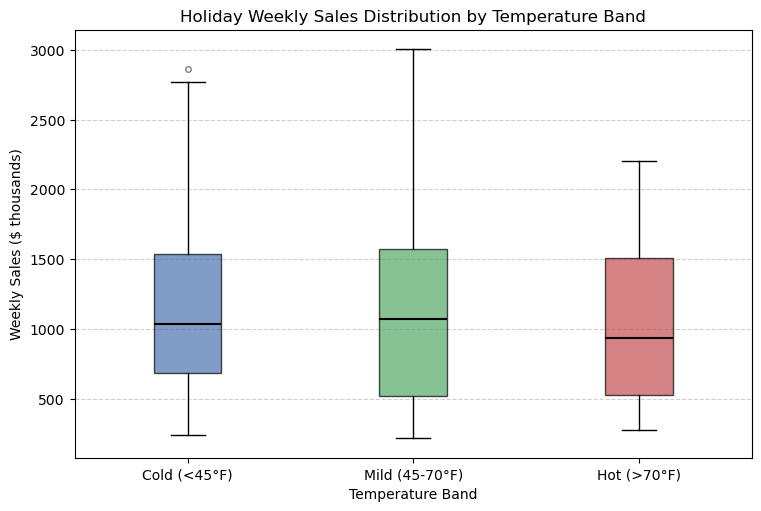

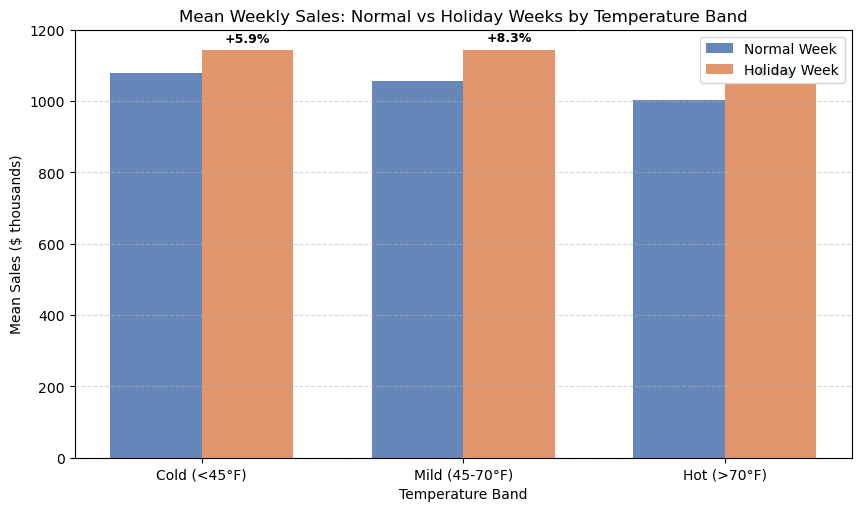

In [24]:
plot_holiday_temp_boxplot(temp_df);
plot_temperature_lift(temp_summary);

# Conclusion (5 marks)

### Achievements
This project investigated the effect of major holiday events on Walmart weekly sales across 45 stores from 2010 to 2012. The analysis shows that holiday events produce significant but uneven gains across stores and weather conditions. Thanksgiving generates the largest overall sales lift, with top-performing stores gaining more than USD 1 million over their normal weeks. In contrast, Christmas sales in this dataset show widespread declines relative to normal weeks because the holiday flag records the post-Christmas clearance week rather than the pre-holiday shopping surge. Furthermore, comparing holiday weeks within identical temperature bands reveals that mild weather (45-70°F) generates the highest percentage gain (+8.3%), cold weather sustains high baseline sales with large holiday spikes (+5.9%), and hot weather yields the smallest increase (+4.4%). Additionally, the two best-selling weeks in the whole dataset, the weeks ending 24 December 2010 and 23 December 2011, are not flagged as holidays, yet they average USD 1.80M and USD 1.71M per store and outsell both Thanksgiving weeks (about USD 1.46M and USD 1.48M).

### Limitations
The primary limitation of this dataset is that weekly sales are reported at the store-wide aggregate level, without department or product breakdowns. This makes it impossible to separate changes in customer foot traffic from changes in basket size, or to observe product substitutions (such as winter apparel versus outdoor garden supplies). Additionally, temperature is recorded as a weekly average without precipitation or snowfall data, which means localized severe weather events like winter blizzards cannot be distinguished from ordinary cold days.

### Future Work
Future work could incorporate department-level scanner data to evaluate how individual merchandise categories respond to holiday promotions and weather shifts. Integrating daily weather observations, including rain and snow depth, would allow a more precise evaluation of extreme weather impacts on store foot traffic and delivery logistics.

# References

Yasser, H. (2021) Walmart Dataset. Kaggle. Available at: https://www.kaggle.com/datasets/yasserh/walmart-dataset (Accessed: 18 November 2026).